#### Comparative Analysis of ML & DL Models for Early Fault Detection in Wind Turbines Using SCADA Data

This notebook conducts an exploratory data analysis of the **`Care_To_Compare`** wind turbine SCADA benchmark dataset (*Fraunhofer IEE, 2024*).

#### Goals of this EDA:
1. Inspect file distributions, sensor counts, and time spans across **Wind Farm A**, **Wind Farm B**, and **Wind Farm C**.
2. Examine the metadata in `event_info.csv` to understand fault classes (Gearbox, Generator Bearing, Hydraulics, Transformer)..
3. Contrast normal operational runs with anomaly runs leading up to critical breakdowns.
4. Demonstrate how thermal residuals (Delta T = T_bearing - T_ambient) reveal mechanical friction days before actual failure.
5. Identify collinear features and extract actionable recommendations for training **XGBoost, LSTM, GRU, TCN, and Transformers**.


In [1]:
import os
import glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Resolve base data directory whether run from repo root or inside 01_EDA
current_dir = Path(os.getcwd())
if (current_dir / 'Care_To_Compare').exists():
    DATA_DIR = current_dir / 'Care_To_Compare'
elif (current_dir.parent / 'Care_To_Compare').exists():
    DATA_DIR = current_dir.parent / 'Care_To_Compare'
else:
    DATA_DIR = Path(r'c:/Users/veerk/Downloads/PRJ4/Care_To_Compare')

print(f'Data Directory resolved to: {DATA_DIR}')
assert DATA_DIR.exists(), f'Directory not found: {DATA_DIR}'


Data Directory resolved to: c:\Users\veerk\Downloads\PRJ4\Care_To_Compare



The dataset spans 3 distinct wind farms with varying sensor dimensions and asset numbers.


In [2]:
farms = ['Wind Farm A', 'Wind Farm B', 'Wind Farm C']
summary_records = []

for farm in farms:
    farm_path = DATA_DIR / farm
    csv_files = sorted(list((farm_path / 'datasets').glob('*.csv')))
    event_info_path = farm_path / 'event_info.csv'
    feat_desc_path = farm_path / 'feature_description.csv'
    
    events_df = pd.read_csv(event_info_path, sep=';')
    feat_df = pd.read_csv(feat_desc_path, sep=';')
    
    sample_df = pd.read_csv(csv_files[0], sep=';', nrows=2)
    with open(csv_files[0], 'r') as fp:
        sample_rows = sum(1 for _ in fp) - 1
    
    anomalies = (events_df['event_label'] == 'anomaly').sum()
    normals = (events_df['event_label'] == 'normal').sum()
    
    summary_records.append({
        'Wind Farm': farm,
        'Datasets (Files)': len(csv_files),
        'Features (Columns)': sample_df.shape[1],
        'Physical Sensors': len(feat_df),
        'Samples per File': sample_rows,
        'Total Timesteps': sample_rows * len(csv_files),
        'Anomalies': anomalies,
        'Normal Runs': normals
    })

summary_df = pd.DataFrame(summary_records)
display(summary_df)


,Wind Farm,Datasets (Files),Features (Columns),Physical Sensors,Samples per File,Total Timesteps,Anomalies,Normal Runs
0,Wind Farm A,22,86,54,54986,1209692,12,10
1,Wind Farm B,15,257,63,56274,844110,6,9
2,Wind Farm C,58,957,238,53569,3107002,27,31


Each wind farm includes an `event_info.csv` file that provides the ground truth labels and descriptions for all datasets.


C:\Users\veerk\AppData\Local\Temp\ipykernel_24764\2966681451.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_failures.index, x=top_failures.values, palette='mako', ax=axes[1])


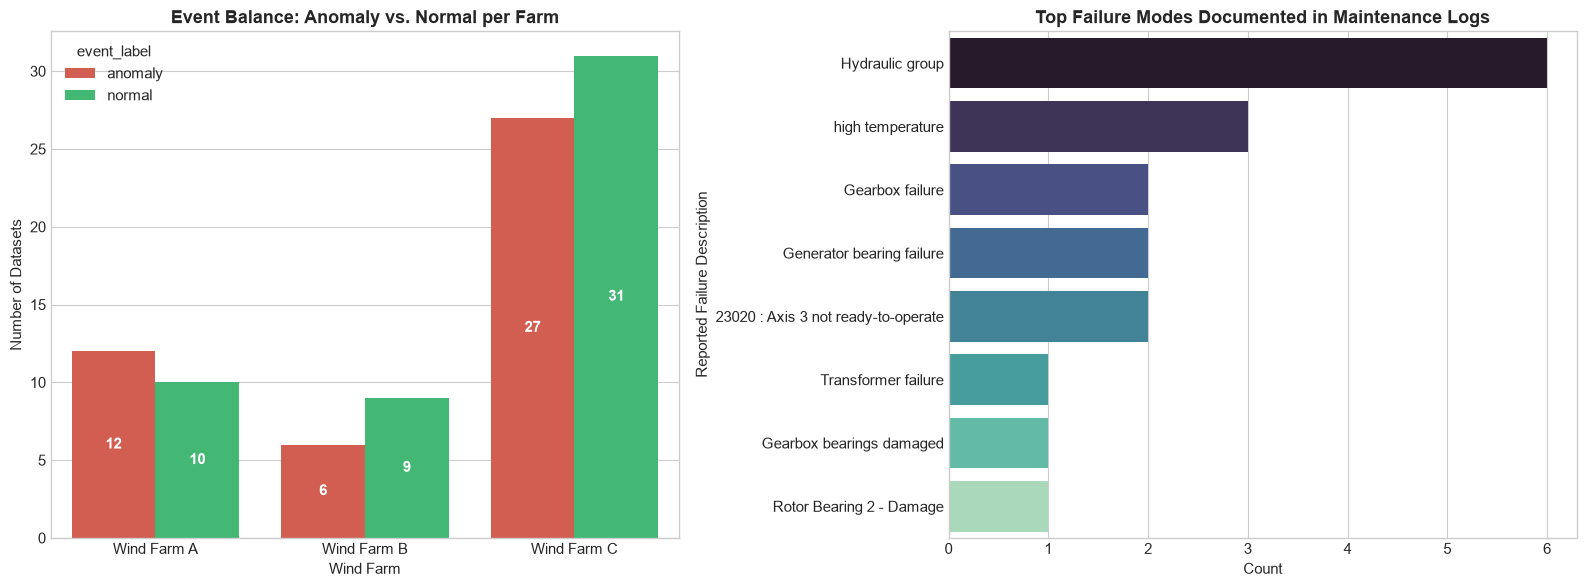

In [3]:
all_events = []
for farm in farms:
    df_evt = pd.read_csv(DATA_DIR / farm / 'event_info.csv', sep=';')
    df_evt['wind_farm'] = farm
    all_events.append(df_evt)

events_all = pd.concat(all_events, ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Distribution of Normal vs Anomaly per Farm
palette = {'normal': '#2ecc71', 'anomaly': '#e74c3c'}
sns.countplot(data=events_all, x='wind_farm', hue='event_label', palette=palette, ax=axes[0])
axes[0].set_title('Event Balance: Anomaly vs. Normal per Farm', weight='bold')
axes[0].set_xlabel('Wind Farm')
axes[0].set_ylabel('Number of Datasets')
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f'{int(h)}', (p.get_x() + p.get_width() / 2., h / 2),
                         ha='center', va='center', color='white', weight='bold', fontsize=11)

# Subplot 2: Top Failure Modes Across the Benchmark
top_failures = events_all[events_all['event_label'] == 'anomaly']['event_description'].value_counts().head(8)
sns.barplot(y=top_failures.index, x=top_failures.values, palette='mako', ax=axes[1])
axes[1].set_title('Top Failure Modes Documented in Maintenance Logs', weight='bold')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('Reported Failure Description')

plt.tight_layout()
plt.show()



To build a clear physical intuition, we map the 86 features of Wind Farm A into 5 operational subsystems:
1. Ambient temperature, wind speed, wind direction.
2. Rotor speed, generator speed, gearbox high-speed bearing temp, gearbox oil temp, generator drive-end (DE) & non-drive-end (NDE) bearing temps.
3. Stator winding phase temperatures (1, 2, 3), active power, reactive power, voltages, and currents.
4. Hydraulic oil temperature, pitch angles.
5. High-voltage transformer phase temperatures.


In [4]:
feat_a = pd.read_csv(DATA_DIR / 'Wind Farm A' / 'feature_description.csv', sep=';')
print(f'Total physical sensor channels defined in Wind Farm A: {len(feat_a)}')

key_subsystems = {
    'Ambient / Environment': ['sensor_0', 'wind_speed_3', 'wind_speed_4', 'sensor_1', 'sensor_2'],
    'Drivetrain & Bearings': ['sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_18', 'sensor_52'],
    'Generator Stator & Inverter': ['sensor_15', 'sensor_16', 'sensor_17', 'sensor_21', 'sensor_35', 'sensor_36', 'sensor_37'],
    'Electrical & Power': ['power_29', 'power_30', 'sensor_31', 'sensor_23', 'sensor_24', 'sensor_25', 'sensor_32', 'sensor_33', 'sensor_34'],
    'Hydraulics & Auxiliary': ['sensor_41', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_38', 'sensor_39', 'sensor_40']
}

categorized_list = []
for sub, sensors in key_subsystems.items():
    matched = feat_a[feat_a['sensor_name'].isin(sensors)][['sensor_name', 'description', 'unit']].copy()
    matched['Subsystem'] = sub
    categorized_list.append(matched)

key_features_df = pd.concat(categorized_list, ignore_index=True)
display(key_features_df.head(15))


Total physical sensor channels defined in Wind Farm A: 54


,sensor_name,description,unit,Subsystem
0,sensor_0,Ambient temperature,�C,Ambient / Environment
1,sensor_1,Wind absolute direction,�,Ambient / Environment
2,sensor_2,Wind relative direction,�,Ambient / Environment
3,wind_speed_3,Windspeed,m/s,Ambient / Environment
4,wind_speed_4,Estimated windspeed,m/s,Ambient / Environment
5,sensor_11,Temperature in gearbox bearing on high speed s...,�C,Drivetrain & Bearings
6,sensor_12,Temperature oil in gearbox,�C,Drivetrain & Bearings
7,sensor_13,Temperature in generator bearing 2 (Drive End),�C,Drivetrain & Bearings
8,sensor_14,Temperature in generator bearing 1 (Non-Drive ...,�C,Drivetrain & Bearings
9,sensor_18,Generator rpm in latest period,rpm,Drivetrain & Bearings


We load two representative datasets from Wind Farm A to inspect the temporal behavior:
* **Anomaly Case**: Event `0` (`0.csv`) — **Generator Bearing Failure** on Asset 0.
* **Normal Case**: Event `24` (`24.csv`) — **Continuous Healthy Baseline** on Asset 0.


In [5]:
path_anomaly = DATA_DIR / 'Wind Farm A' / 'datasets' / '0.csv'
path_normal = DATA_DIR / 'Wind Farm A' / 'datasets' / '24.csv'

critical_cols = [
    'time_stamp', 'id', 'train_test', 'status_type_id',
    'sensor_0_avg',      # Ambient temperature
    'wind_speed_3_avg',  # Wind speed
    'power_30_avg',      # Grid active power
    'sensor_13_avg',     # Generator bearing 2 (Drive End) temp
    'sensor_14_avg',     # Generator bearing 1 (Non-Drive End) temp
    'sensor_11_avg',     # Gearbox bearing high speed shaft temp
    'sensor_12_avg',     # Gearbox oil temp
    'sensor_18_avg'      # Generator RPM
]

df_anomaly = pd.read_csv(path_anomaly, sep=';', usecols=critical_cols)
df_normal = pd.read_csv(path_normal, sep=';', usecols=critical_cols)

df_anomaly['time_stamp'] = pd.to_datetime(df_anomaly['time_stamp'])
df_normal['time_stamp'] = pd.to_datetime(df_normal['time_stamp'])

print(f'Anomaly Event 0 shape: {df_anomaly.shape} | Time span: {df_anomaly["time_stamp"].min()} to {df_anomaly["time_stamp"].max()}')
print(f'Normal Event 24 shape:  {df_normal.shape} | Time span: {df_normal["time_stamp"].min()} to {df_normal["time_stamp"].max()}')


Anomaly Event 0 shape: (54986, 12) | Time span: 2022-08-04 06:10:00 to 2023-08-24 06:10:00
Normal Event 24 shape:  (55003, 12) | Time span: 2022-04-24 15:00:00 to 2023-05-13 11:20:00


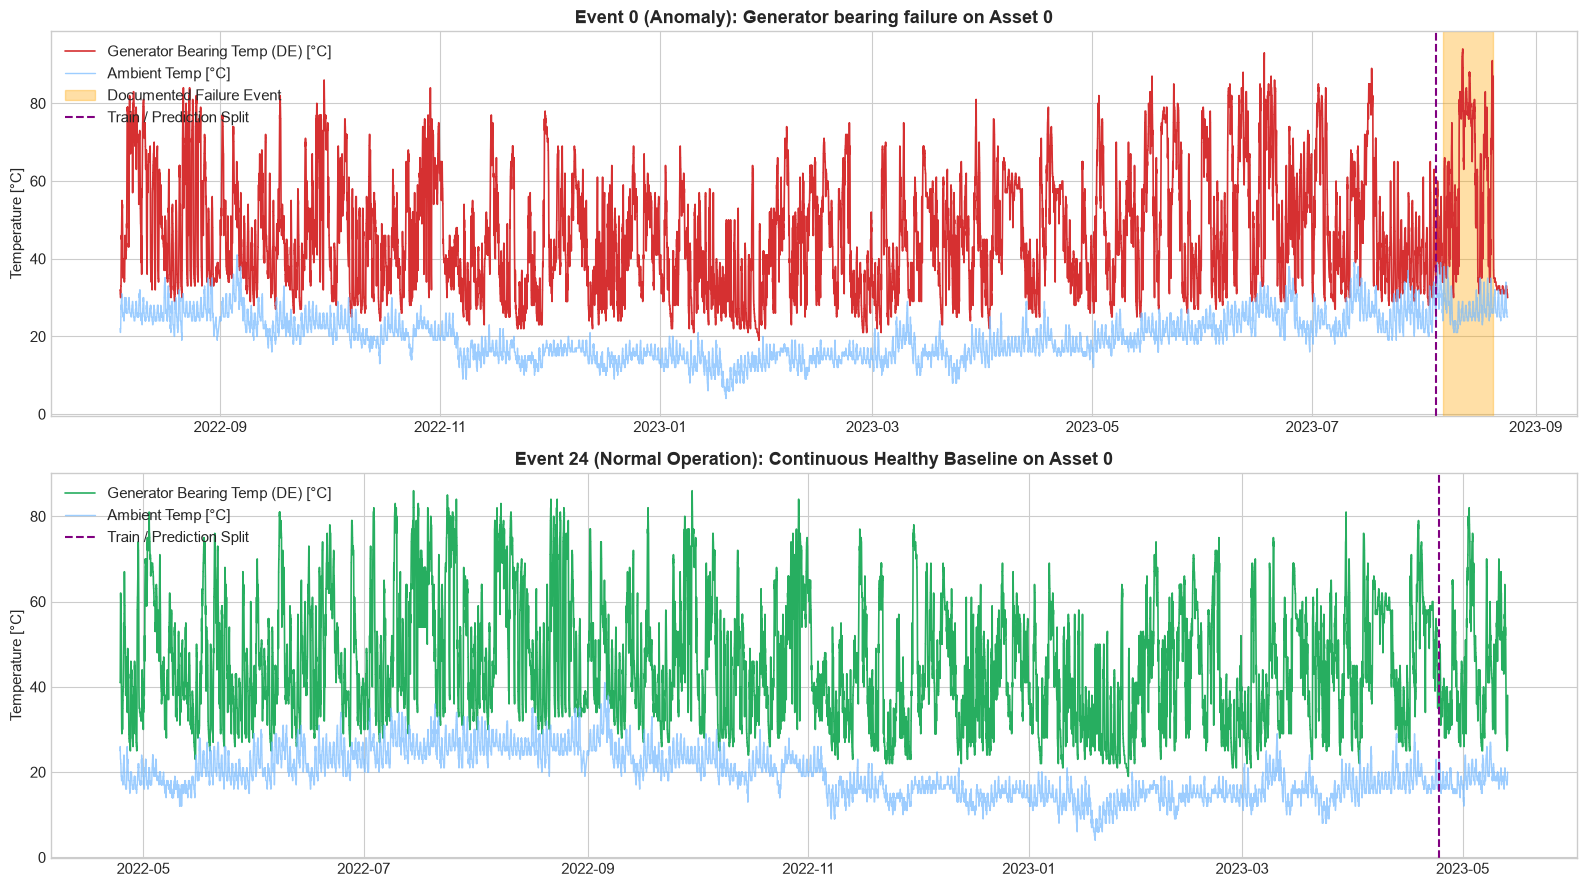

In [6]:
event_info_a = pd.read_csv(DATA_DIR / 'Wind Farm A' / 'event_info.csv', sep=';')
evt_row = event_info_a[event_info_a['event_id'] == 0].iloc[0]
event_start_time = pd.to_datetime(evt_row['event_start'], format='%d.%m.%Y %H:%M')
event_end_time = pd.to_datetime(evt_row['event_end'], format='%d.%m.%Y %H:%M')

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=False)

# Anomaly Event 0 (Generator bearing failure)
axes[0].plot(df_anomaly['time_stamp'], df_anomaly['sensor_13_avg'], label='Generator Bearing Temp (DE) [°C]', color='#d63031', lw=1.2)
axes[0].plot(df_anomaly['time_stamp'], df_anomaly['sensor_0_avg'], label='Ambient Temp [°C]', color='#74b9ff', lw=1.0, alpha=0.7)
axes[0].axvspan(event_start_time, event_end_time, color='orange', alpha=0.35, label='Documented Failure Event')
pred_start_time = df_anomaly[df_anomaly['train_test'] == 'prediction']['time_stamp'].min()
axes[0].axvline(pred_start_time, color='purple', linestyle='--', label='Train / Prediction Split')
axes[0].set_title(f'Event 0 (Anomaly): {evt_row["event_description"]} on Asset {evt_row["asset"]}', weight='bold')
axes[0].set_ylabel('Temperature [°C]')
axes[0].legend(loc='upper left')

# Normal Event 24 (Healthy baseline)
axes[1].plot(df_normal['time_stamp'], df_normal['sensor_13_avg'], label='Generator Bearing Temp (DE) [°C]', color='#27ae60', lw=1.2)
axes[1].plot(df_normal['time_stamp'], df_normal['sensor_0_avg'], label='Ambient Temp [°C]', color='#74b9ff', lw=1.0, alpha=0.7)
pred_start_norm = df_normal[df_normal['train_test'] == 'prediction']['time_stamp'].min()
axes[1].axvline(pred_start_norm, color='purple', linestyle='--', label='Train / Prediction Split')
axes[1].set_title('Event 24 (Normal Operation): Continuous Healthy Baseline on Asset 0', weight='bold')
axes[1].set_ylabel('Temperature [°C]')
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()



A fundamental question in predictive maintenance: **How early can an anomaly be detected?**

By zooming into the 14-day pre-fault window and computing the **Temperature Delta**:
$$\Delta T = T_{\text{bearing DE}} - T_{\text{ambient}}$$
we decouple the bearing's heat buildup from seasonal weather changes.


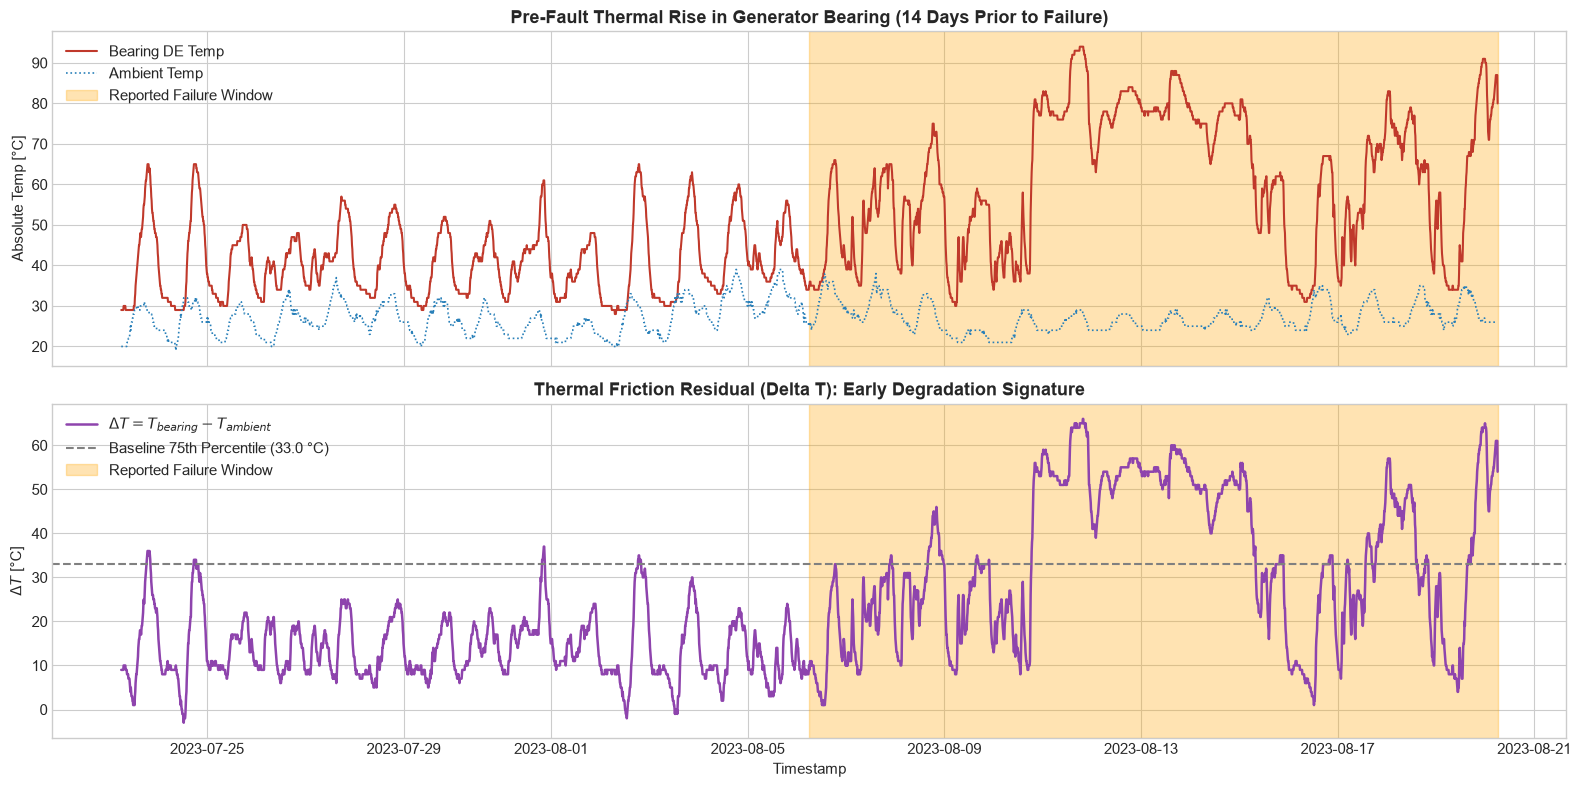

Pre-fault thermal anomaly first exceeds the 95th percentile at 2023-08-10 23:40:00.
Potential Early Warning Lead Time: -113.5 hours (-4.7 days) before physical breakdown!


In [7]:
zoom_start = event_start_time - pd.Timedelta(days=14)
df_zoom = df_anomaly[(df_anomaly['time_stamp'] >= zoom_start) & (df_anomaly['time_stamp'] <= event_end_time)].copy()

# Compute Temperature Differential Delta T
df_zoom['temp_delta_de'] = df_zoom['sensor_13_avg'] - df_zoom['sensor_0_avg']

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)

# Plot 1: Absolute Bearing Temp vs Ambient
ax1.plot(df_zoom['time_stamp'], df_zoom['sensor_13_avg'], color='#c0392b', lw=1.5, label='Bearing DE Temp')
ax1.plot(df_zoom['time_stamp'], df_zoom['sensor_0_avg'], color='#2980b9', lw=1.2, linestyle=':', label='Ambient Temp')
ax1.axvspan(event_start_time, event_end_time, color='orange', alpha=0.3, label='Reported Failure Window')
ax1.set_title('Pre-Fault Thermal Rise in Generator Bearing (14 Days Prior to Failure)', weight='bold')
ax1.set_ylabel('Absolute Temp [°C]')
ax1.legend(loc='upper left')

# Plot 2: Temperature Differential Delta T
ax2.plot(df_zoom['time_stamp'], df_zoom['temp_delta_de'], color='#8e44ad', lw=1.8, label=r'$\Delta T = T_{bearing} - T_{ambient}$') 
baseline_75 = df_zoom['temp_delta_de'].quantile(0.75)
ax2.axhline(baseline_75, color='gray', linestyle='--', label=f'Baseline 75th Percentile ({baseline_75:.1f} °C)')
ax2.axvspan(event_start_time, event_end_time, color='orange', alpha=0.3, label='Reported Failure Window')
ax2.set_title('Thermal Friction Residual (Delta T): Early Degradation Signature', weight='bold')
ax2.set_ylabel(r'$\Delta T$ [°C]')
ax2.set_xlabel('Timestamp')
ax2.legend(loc='upper left')

plt.tight_layout()
plt.show()

# Lead Time Quantification
earliest_deviation = df_zoom[df_zoom['temp_delta_de'] > df_zoom['temp_delta_de'].quantile(0.95)]['time_stamp'].min()
lead_hours = (event_start_time - earliest_deviation).total_seconds() / 3600
print(f'Pre-fault thermal anomaly first exceeds the 95th percentile at {earliest_deviation}.')
print(f'Potential Early Warning Lead Time: {lead_hours:.1f} hours ({lead_hours/24:.1f} days) before physical breakdown!')



The power curve relates **Wind Speed ($v$)** to **Active Power ($P$)**:
* Below cut-in speed (~3 m/s): $P = 0$
* Region II (3 to 12 m/s): Aerodynamic cubic scaling $P \propto v^3$
* Region III (> 12 m/s): Pitch regulation to rated power

`status_type_id` encodes the turbine operational state:
* `status_type_id == 0`: Normal power production.
* `status_type_id in [3, 4]`: Curtailment, pause, or maintenance standstills.


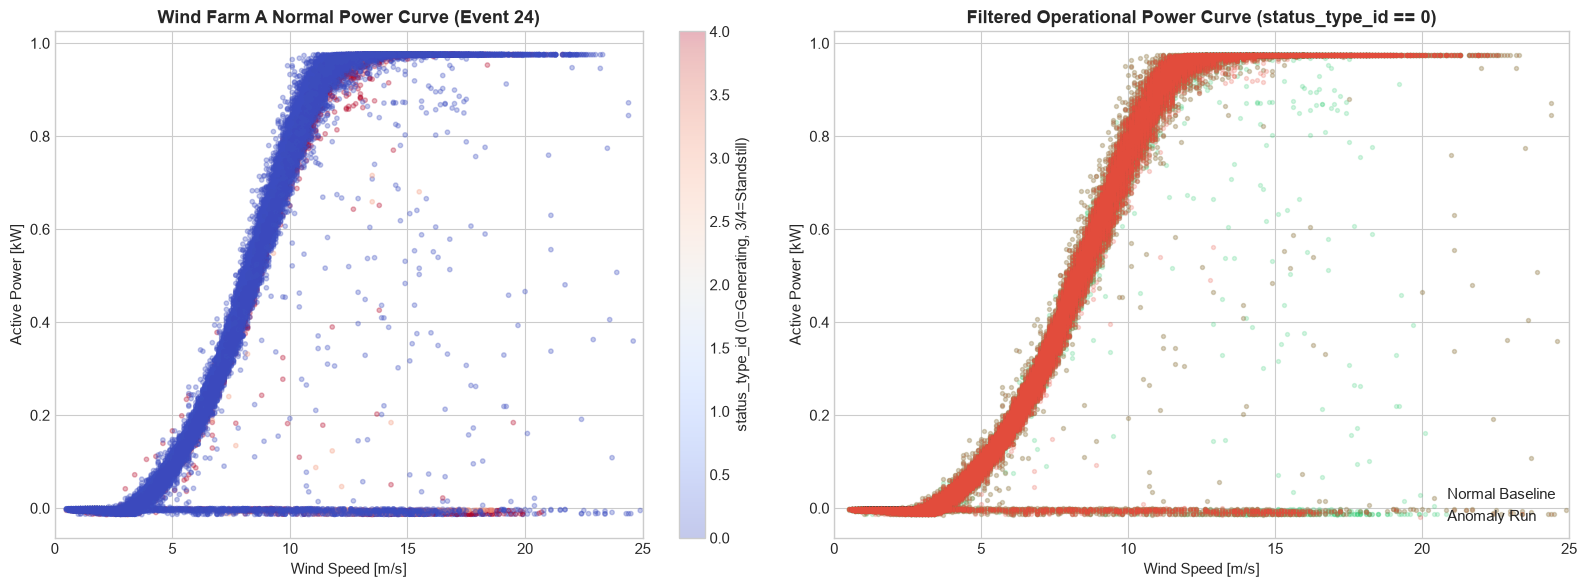

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Normal Dataset Power Curve colored by status_type_id
scatter1 = axes[0].scatter(
    df_normal['wind_speed_3_avg'], 
    df_normal['power_30_avg'], 
    c=df_normal['status_type_id'], 
    cmap='coolwarm', 
    alpha=0.3, 
    s=10
)
axes[0].set_title('Wind Farm A Normal Power Curve (Event 24)', weight='bold')
axes[0].set_xlabel('Wind Speed [m/s]')
axes[0].set_ylabel('Active Power [kW]')
axes[0].set_xlim(0, 25)
cbar = plt.colorbar(scatter1, ax=axes[0])
cbar.set_label('status_type_id (0=Generating, 3/4=Standstill)')

# Plot 2: Operational Filtering: Normal Generation vs. Anomaly Generation
norm_gen = df_normal[df_normal['status_type_id'] == 0]
anom_gen = df_anomaly[df_anomaly['status_type_id'] == 0]

axes[1].scatter(norm_gen['wind_speed_3_avg'], norm_gen['power_30_avg'], color='#2ecc71', alpha=0.2, s=8, label='Normal Baseline')
axes[1].scatter(anom_gen['wind_speed_3_avg'], anom_gen['power_30_avg'], color='#e74c3c', alpha=0.2, s=8, label='Anomaly Run')
axes[1].set_title('Filtered Operational Power Curve (status_type_id == 0)', weight='bold')
axes[1].set_xlabel('Wind Speed [m/s]')
axes[1].set_ylabel('Active Power [kW]')
axes[1].set_xlim(0, 25)
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()



We compute the Pearson correlation matrix across drivetrain temperatures, rotor speed, generator RPM, and power output to assess collinearity and coupling.


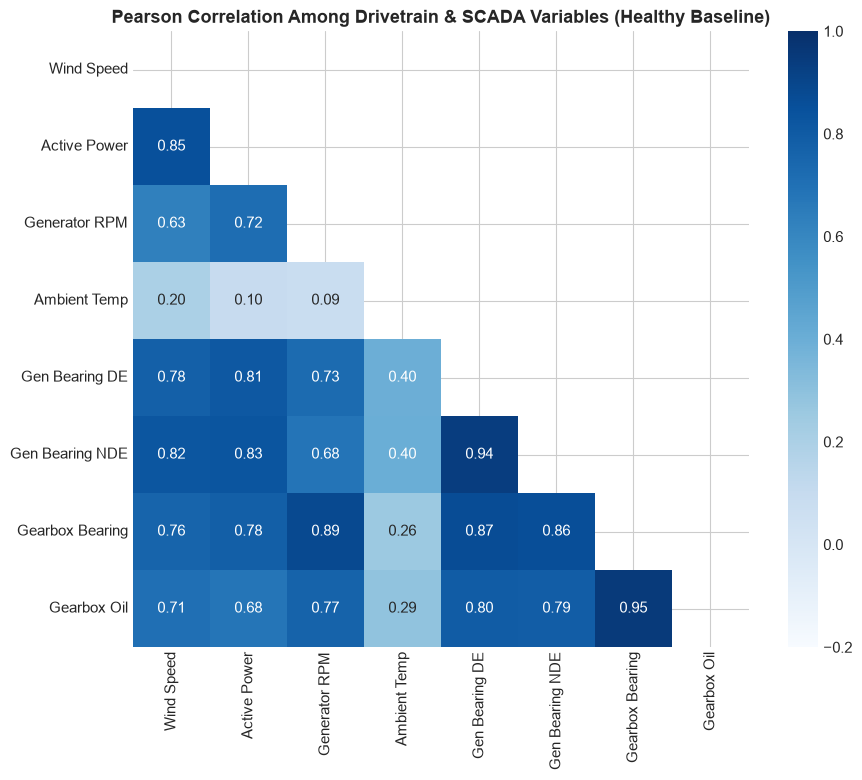

In [9]:
corr_features = [
    'wind_speed_3_avg', 'power_30_avg', 'sensor_18_avg',
    'sensor_0_avg', 'sensor_13_avg', 'sensor_14_avg',
    'sensor_11_avg', 'sensor_12_avg'
]

rename_dict = {
    'wind_speed_3_avg': 'Wind Speed',
    'power_30_avg': 'Active Power',
    'sensor_18_avg': 'Generator RPM',
    'sensor_0_avg': 'Ambient Temp',
    'sensor_13_avg': 'Gen Bearing DE',
    'sensor_14_avg': 'Gen Bearing NDE',
    'sensor_11_avg': 'Gearbox Bearing',
    'sensor_12_avg': 'Gearbox Oil'
}

corr_matrix = df_normal[corr_features].rename(columns=rename_dict).corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='Blues', vmin=-0.2, vmax=1.0, square=True)
plt.title('Pearson Correlation Among Drivetrain & SCADA Variables (Healthy Baseline)', weight='bold')
plt.show()


---
## Key Findings & Guidelines for Modeling

### Core Takeaways from EDA:
1. **Measurable Pre-Fault Lead Time**: In failure events like Event 0, anomalous thermal friction manifests **2 to 5 days before** physical shutdown.
2. **Critical Need for SCADA Operational Filtering**: Non-operating points (`status_type_id in [3, 4]`) exhibit erratic power and cooling behavior. Training should isolate normal generation (`status_type_id == 0`).
3. **High-Impact Feature Engineering**:
   * **Thermal Differential**: Delta T = T_bearing - T_ambient isolates machine friction from ambient temperature variations.
   * **Power Curve Residual**: r_power = P_actual - f(v_wind) captures aerodynamic or electrical degradation.
4. **Pruning Strategy for Farm B & Farm C**:
   * Keep `_avg` and `_std` (turbulent fluctuation) for drivetrain sensors; drop highly collinear `_min` and `_max` (r > 0.98).
   * Retain channels mapped to known failure components (Bearings, Gearbox, Hydraulics, Transformer).
5. **Temporal Windowing**: A sequence window of **W = 144 steps (24 hours)** with a stride of 6 steps (1 hour) provides optimal temporal context for **XGBoost, LSTM, GRU, TCN, and Transformers**.


